# Telco Customer Churn Prediction

## Project Overview

Customer churn represents customers discontinuing their relationship with a
service provider. Identifying customers who are likely to churn can help a
business take proactive retention measures.

The objective of this project is to develop a machine learning model that can
identify customers at risk of churn while also investigating the customer,
service, contract, and billing characteristics associated with churn.

### Modeling Objective

Because failing to identify a customer who eventually churns may be more costly
than incorrectly flagging a customer who remains, **recall for the churn class
is treated as the primary evaluation metric**.

Precision, F1-score, and the confusion matrix are also considered to ensure
that improvements in recall do not result in an unreasonable number of false
positives.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy.stats import chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Data splitting and cross-validation
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    recall_score,
    precision_score,
    f1_score
)

# Notebook display settings
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)


## 1. Data Loading

In [2]:
churn_data = pd.read_csv("../data/Telco-Customer-Churn.csv")

### Dataset Overview and Initial Inspection

In [3]:
churn_data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
churn_data.shape

(7032, 21)

In [5]:
churn_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


In [6]:
churn_data.nunique()

customerID          7032
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                72
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1584
TotalCharges        6530
Churn                  2
dtype: int64

In [7]:
churn_data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
churn_data.duplicated().sum()

np.int64(0)

In [8]:
churn_data["customerID"].duplicated().sum()

np.int64(0)

### Initial Inspection Summary

- The dataset contains **7,032 customer records and 21 features**.
- The variables include both numerical and categorical features describing customer demographics, subscribed services, contract details, and billing information.
- No missing values or duplicate records were identified during the initial inspection.
- Each `customerID` is unique, confirming that each row represents a distinct customer.
- `customerID` functions only as an identifier and will therefore be excluded from predictive modeling.

## 2. Exploratory Data Analysis

### 2.1 Target Variable Distribution

In [11]:
eda = churn_data.copy()  # Create a copy of the original DataFrame for EDA

In [12]:
churn_summary = eda["Churn"].value_counts().to_frame(name="Count")
churn_summary["Percentage"] = (
    eda["Churn"].value_counts(normalize=True) * 100
)

churn_summary

,Count,Percentage
Churn,,
No,5163,73.42
Yes,1869,26.58


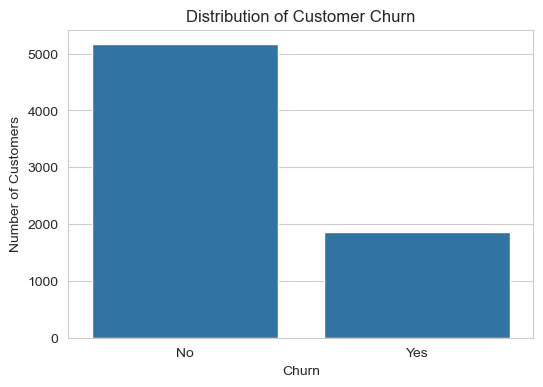

In [15]:
plt.figure(figsize=(6, 4))

sns.countplot(data=eda, x="Churn")

plt.title("Distribution of Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

#### Finding

The target variable is moderately imbalanced, with approximately **73% of
customers remaining and 27% churning**.

This imbalance is important for model evaluation because a model could achieve
relatively high accuracy by favoring the majority non-churn class while still
failing to identify many customers who actually churn. Therefore, recall,
precision, F1-score, and the confusion matrix will be considered alongside
accuracy during model evaluation.

### 2.2 Numerical Feature Analysis

In [16]:
numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

eda[numerical_columns].describe()

,tenure,MonthlyCharges,TotalCharges
count,7032.00,7032.00,7032.00
mean,32.42,64.80,2283.30
std,24.55,30.09,2266.77
min,1.00,18.25,18.80
25%,9.00,35.59,401.45
50%,29.00,70.35,1397.47
75%,55.00,89.86,3794.74
max,72.00,118.75,8684.80


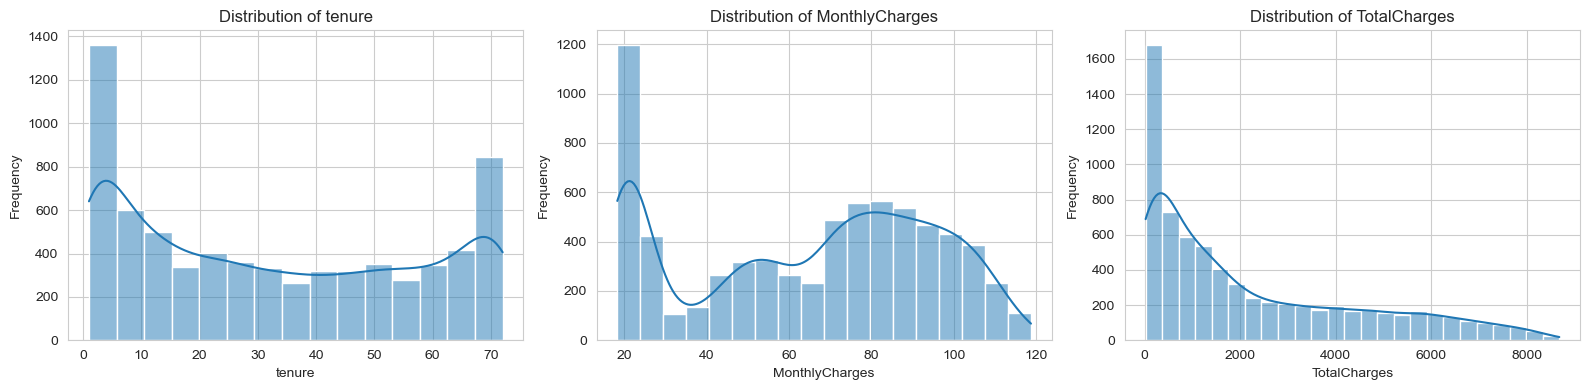

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

for ax, col in zip(axes, numerical_columns):
    sns.histplot(data=eda, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 2.3 Categorical Feature Analysis

In [19]:
categorical_columns = eda.select_dtypes(include="object").columns
categorical_columns = categorical_columns.drop(["customerID", "Churn"])

In [20]:
for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(eda[col].value_counts())


--- gender ---
gender
Male      3549
Female    3483
Name: count, dtype: int64

--- Partner ---
Partner
No     3639
Yes    3393
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2099
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6352
No      680
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  3385
Yes                 2967
No phone service     680
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     3497
Yes                    2015
No internet service    1520
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No                     3087
Yes                    2425
No internet service    1520
Name: count, dtype: int64

--- DeviceProtection ---
DeviceProtection
No                     3094
Yes                    2418
No internet service   

### 2.4 Categorical Features and Churn

In [22]:
for col in categorical_columns:
    summary = (
        eda.groupby(col, observed=True)["Churn"]
        .agg(
            churn_rate=lambda x: (x == "Yes").mean() * 100,
            churned_count=lambda x: (x == "Yes").sum(),
            n_customers="count"
        )
        .round(1)
    )

    print(f"\n--- Churn by {col} ---")
    print(summary)


--- Churn by gender ---
        churn_rate  churned_count  n_customers
gender                                        
Female       27.00            939         3483
Male         26.20            930         3549

--- Churn by Partner ---
         churn_rate  churned_count  n_customers
Partner                                        
No            33.00           1200         3639
Yes           19.70            669         3393

--- Churn by Dependents ---
            churn_rate  churned_count  n_customers
Dependents                                        
No               31.30           1543         4933
Yes              15.50            326         2099

--- Churn by PhoneService ---
              churn_rate  churned_count  n_customers
PhoneService                                        
No                 25.00            170          680
Yes                26.70           1699         6352

--- Churn by MultipleLines ---
                  churn_rate  churned_count  n_customers
Mult

### 2.5 Key Categorical Relationship with Churn

In [23]:
key_categorical = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling"
]

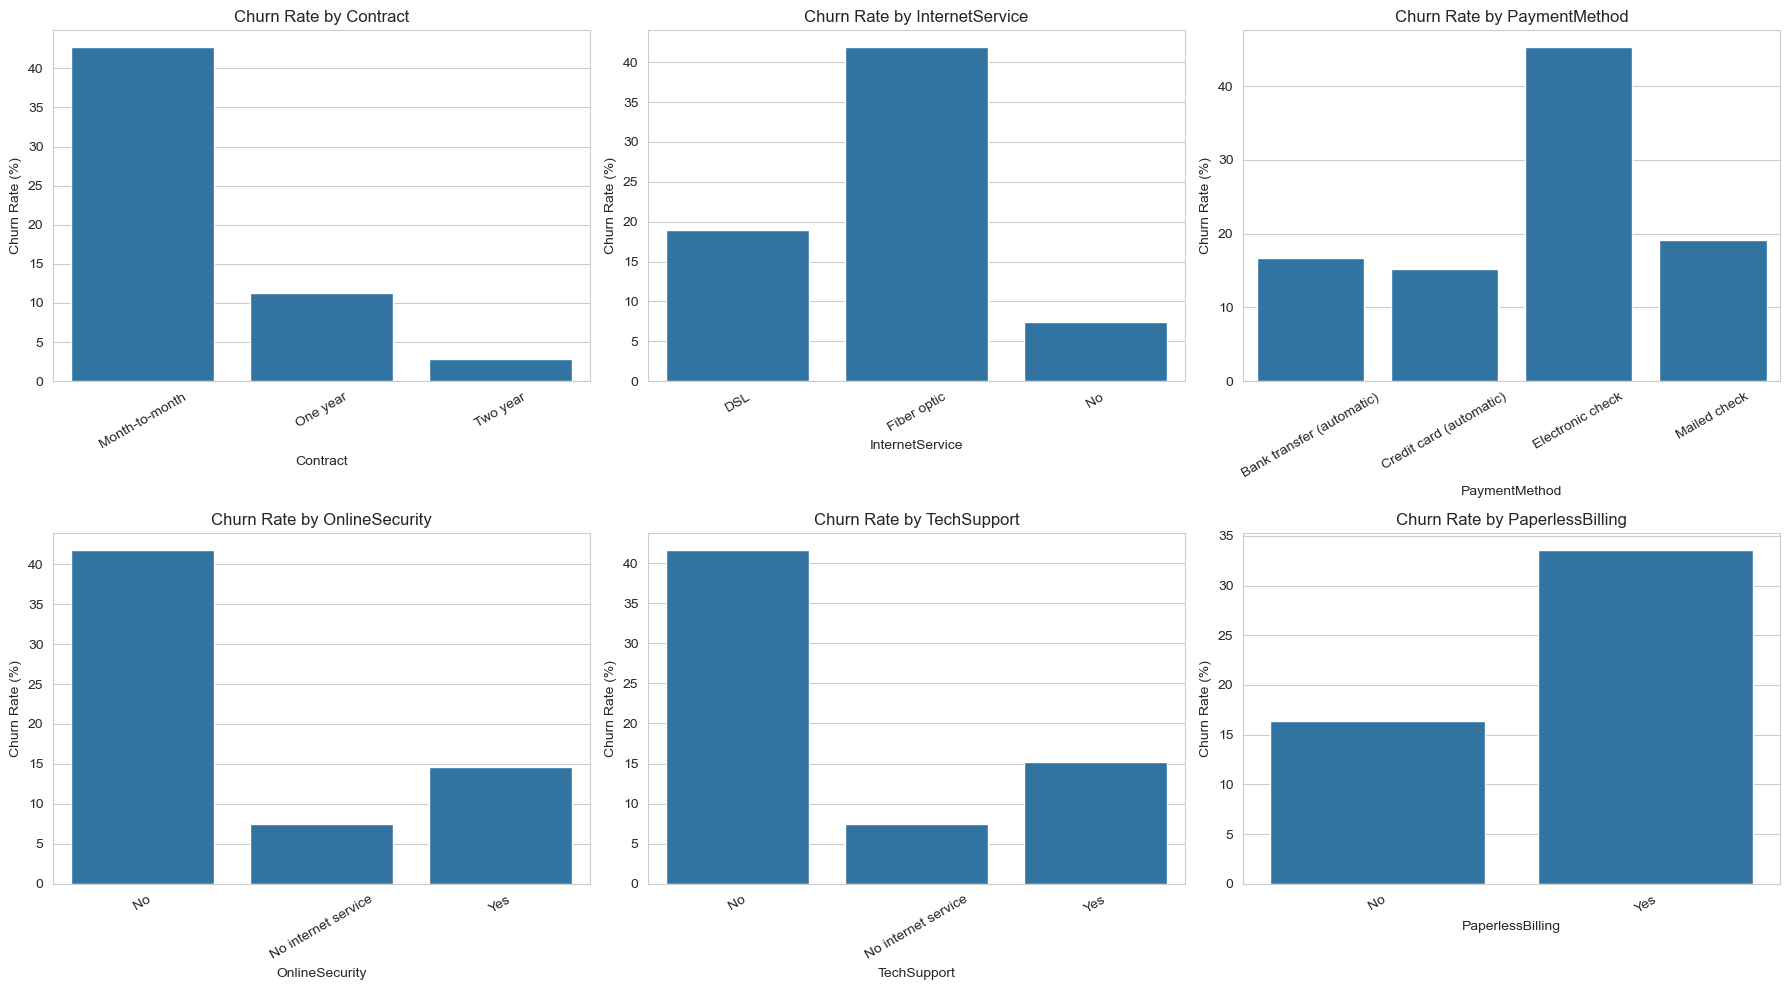

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, col in zip(axes, key_categorical):
    
    churn_rates = (
        eda.groupby(col, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Churn Rate")
    )

    sns.barplot(
        data=churn_rates,
        x=col,
        y="Churn Rate",
        ax=ax
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

#### Key Findings

Several categorical features show clear differences in churn behaviour:

- **Contract:** Month-to-month customers have a substantially higher churn rate than customers on one- or two-year contracts, suggesting a strong relationship between contract type and churn.
- **Internet Service:** Fiber-optic customers show the highest churn rate, while customers without internet service have the lowest.
- **Payment Method:** Customers using electronic checks have a noticeably higher churn rate than those using the other payment methods.
- **Online Security and Tech Support:** Customers without these services show considerably higher churn rates than customers who have them.
- **Paperless Billing:** Customers using paperless billing show a higher churn rate than those who do not.

These patterns indicate potentially important relationships with churn. However, the plots alone do not establish statistical significance or causation, so these features will be investigated further during feature-selection and relationship analysis.

### 2.6 Numerical Features and Churn

In [25]:
eda.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(
    ["mean", "median", "std"]
).round(2)

tenure              MonthlyCharges              TotalCharges          \
        mean median   std           mean median   std         mean  median   
Churn                                                                        
No     37.65  38.00 24.08          61.31  64.45 31.09      2555.34 1683.60   
Yes    17.98  10.00 19.53          74.44  79.65 24.67      1531.80  703.55   

               
          std  
Churn          
No    2329.46  
Yes   1890.82

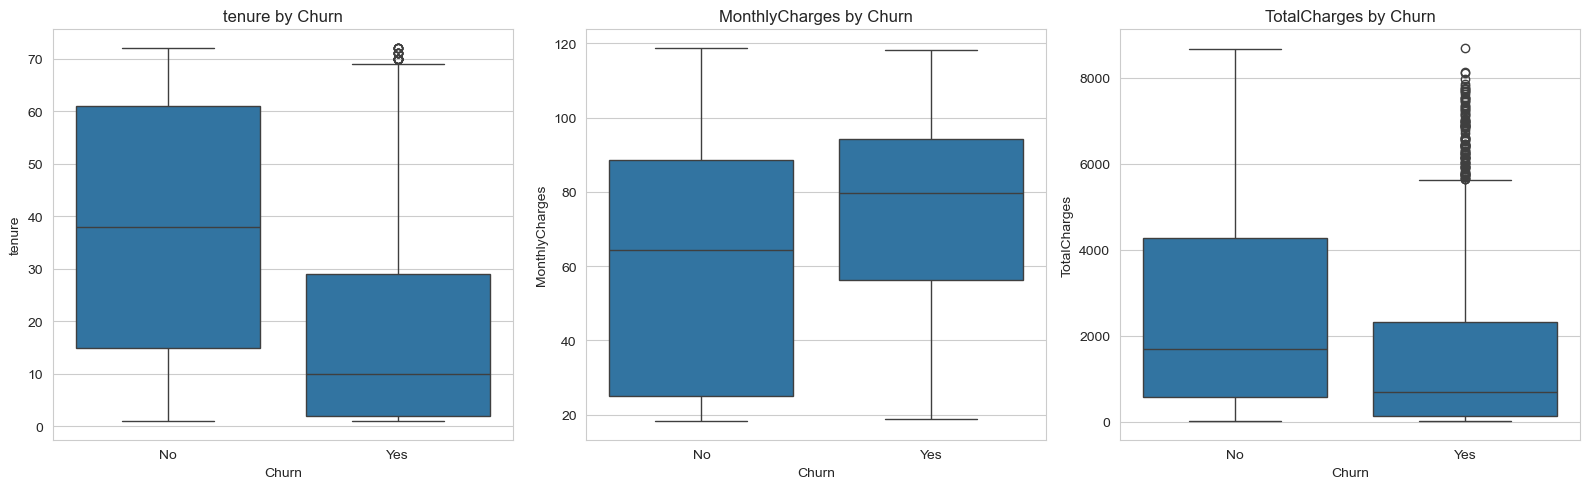

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

for ax, col in zip(axes, numerical_columns):
    sns.boxplot(data=eda, x="Churn", y=col, ax=ax)
    ax.set_title(f"{col} by Churn")
    ax.set_xlabel("Churn")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

#### Key Findings

- Customers who churn tend to have substantially shorter **tenure**, with a median of 10 months compared with 38 months for customers who remain.
- Churned customers generally have higher **MonthlyCharges**, with a median monthly charge of 79.65 compared with 64.45 for non-churned customers.
- Despite having higher monthly charges, churned customers have lower **TotalCharges** overall. This is consistent with their shorter tenure, since customers who leave earlier have had less time to accumulate charges.

These results suggest that tenure and customer charges are associated with churn. The relationship between `tenure`, `MonthlyCharges`, and `TotalCharges` will be examined further during feature analysis.

## 3. Feature Selection and Relationship Analysis

The exploratory analysis revealed differences in churn rates across several
customer characteristics. This section examines these relationships more
closely to assess statistical association, identify redundant information,
and determine which features should be carried forward for modeling.

### 3.1 Categorical Feature Significance — Chi-Square Test

In [29]:
chi_square_results = []

for col in categorical_columns:
    contingency_table = pd.crosstab(eda[col], eda["Churn"])

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    chi_square_results.append({
        "Feature": col,
        "Chi-Square": chi2,
        "p-value": p_value
    })

chi_square_results = (
    pd.DataFrame(chi_square_results)
    .sort_values("Chi-Square", ascending=False)
    .reset_index(drop=True)
)

display(chi_square_results.style.hide(axis="index"))

Feature,Chi-Square,p-value
Contract,1179.545829,0.000000
OnlineSecurity,846.677389,0.000000
TechSupport,824.925564,0.000000
InternetService,728.695614,0.000000
PaymentMethod,645.429900,0.000000
OnlineBackup,599.175185,0.000000
DeviceProtection,555.880327,0.000000
StreamingMovies,374.268432,0.000000
StreamingTV,372.456502,0.000000
PaperlessBilling,256.874908,0.000000


#### Interpretation

The Chi-square test was used to evaluate whether each categorical feature has
a statistically significant association with churn.

A small p-value provides evidence against the assumption that the feature and
churn are independent. However, statistical significance alone does not imply
that a feature is practically important or useful for prediction.

Therefore, the Chi-square results are used as an initial screening step and
are considered together with churn-rate differences, feature redundancy, and
conditional relationships.

### 3.2 Practical Significance and Redundancy Analysis

Statistical significance does not necessarily imply practical importance.
Therefore, features with weak churn-rate differences or potentially overlapping
information were examined more closely before making feature-selection decisions.

#### Gender, Phone Service, and Multiple Lines

In [30]:
features_to_review = ["gender", "PhoneService", "MultipleLines"]

for col in features_to_review:
    summary = (
        eda.groupby(col)["Churn"]
        .agg(
            churn_rate=lambda x: (x == "Yes").mean() * 100,
            churned_count=lambda x: (x == "Yes").sum(),
            n_customers="count"
        )
        .round(1)
    )

    print(f"\n--- {col} ---")
    display(summary)


--- gender ---


,churn_rate,churned_count,n_customers
gender,,,
Female,27.00,939,3483
Male,26.20,930,3549



--- PhoneService ---


,churn_rate,churned_count,n_customers
PhoneService,,,
No,25.00,170,680
Yes,26.70,1699,6352



--- MultipleLines ---


,churn_rate,churned_count,n_customers
MultipleLines,,,
No,25.10,849,3385
No phone service,25.00,170,680
Yes,28.60,850,2967


In [31]:
pd.crosstab(
    eda["PhoneService"],
    eda["MultipleLines"],
    margins=True
)

MultipleLines,No,No phone service,Yes,All
PhoneService,,,,
No,0,680,0,680
Yes,3385,0,2967,6352
All,3385,680,2967,7032


#### Phone Service and Multiple Lines

`PhoneService` and `MultipleLines` show structural redundancy. Customers without
phone service are represented by the `"No phone service"` category in
`MultipleLines`, while customers with phone service are further distinguished
by whether they have multiple lines.

Therefore, `MultipleLines` retains the information contained in `PhoneService`
while also providing additional detail. `PhoneService` can consequently be
excluded from the modeling feature set.

Although `MultipleLines` shows only a small difference in churn rates across
its categories, it will be retained initially and its usefulness evaluated
during modeling.

#### Internet Service and Internet Add-on Features

In [33]:
internet_addons = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for col in internet_addons:
    print(f"\n--- InternetService vs {col} ---")
    display(
        pd.crosstab(
            eda["InternetService"],
            eda[col],
            normalize="index"
        ).round(3)
    )


--- InternetService vs OnlineSecurity ---


OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,0.51,0.00,0.49
Fiber optic,0.73,0.00,0.27
No,0.00,1.00,0.00



--- InternetService vs OnlineBackup ---


OnlineBackup,No,No internet service,Yes
InternetService,,,
DSL,0.55,0.00,0.45
Fiber optic,0.57,0.00,0.43
No,0.00,1.00,0.00



--- InternetService vs DeviceProtection ---


DeviceProtection,No,No internet service,Yes
InternetService,,,
DSL,0.56,0.00,0.44
Fiber optic,0.56,0.00,0.44
No,0.00,1.00,0.00



--- InternetService vs TechSupport ---


TechSupport,No,No internet service,Yes
InternetService,,,
DSL,0.51,0.00,0.49
Fiber optic,0.72,0.00,0.28
No,0.00,1.00,0.00



--- InternetService vs StreamingTV ---


StreamingTV,No,No internet service,Yes
InternetService,,,
DSL,0.61,0.00,0.39
Fiber optic,0.43,0.00,0.56
No,0.00,1.00,0.00



--- InternetService vs StreamingMovies ---


StreamingMovies,No,No internet service,Yes
InternetService,,,
DSL,0.59,0.00,0.41
Fiber optic,0.43,0.00,0.57
No,0.00,1.00,0.00


#### Finding

The six internet add-on features contain a `"No internet service"` category that
corresponds directly to customers whose `InternetService` value is `"No"`.
Therefore, this category repeats information already represented by
`InternetService`.

However, the add-on features are not completely redundant. Among customers
with internet service, they still distinguish between customers who subscribe
to each service and those who do not.

The add-on features will therefore be retained for further analysis, while the
redundant `"No internet service"` category will be addressed during
preprocessing.

### 3.3 Conditional Analysis of Internet Add-ons

In [34]:
internet_customers = eda[eda["InternetService"] != "No"]

for addon in internet_addons:
    churn_rates = (
        internet_customers
        .groupby(["InternetService", addon], observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .unstack()
        .round(1)
    )

    print(f"\n--- Churn Rate by InternetService and {addon} ---")
    display(churn_rates)


--- Churn Rate by InternetService and OnlineSecurity ---


OnlineSecurity,No,Yes
InternetService,,
DSL,28.00,9.50
Fiber optic,49.40,21.80



--- Churn Rate by InternetService and OnlineBackup ---


OnlineBackup,No,Yes
InternetService,,
DSL,25.70,10.70
Fiber optic,50.80,30.30



--- Churn Rate by InternetService and DeviceProtection ---


DeviceProtection,No,Yes
InternetService,,
DSL,25.20,11.00
Fiber optic,50.00,31.50



--- Churn Rate by InternetService and TechSupport ---


TechSupport,No,Yes
InternetService,,
DSL,27.80,9.70
Fiber optic,49.40,22.60



--- Churn Rate by InternetService and StreamingTV ---


StreamingTV,No,Yes
InternetService,,
DSL,22.70,13.30
Fiber optic,45.30,39.30



--- Churn Rate by InternetService and StreamingMovies ---


StreamingMovies,No,Yes
InternetService,,
DSL,22.40,14.00
Fiber optic,45.80,38.90


#### Finding

After restricting the analysis to customers with internet service, the add-on
features continued to show different levels of association with churn.

`OnlineSecurity` and `TechSupport` showed particularly strong churn-rate
differences within both DSL and Fiber Optic customers, while `OnlineBackup`
also retained a meaningful relationship.

The differences associated with `DeviceProtection`, `StreamingTV`, and
`StreamingMovies` were weaker, suggesting that their predictive contribution
may depend more heavily on other customer characteristics.

Therefore, the internet add-on features will not be removed solely on the
basis of their structural relationship with `InternetService`. Their usefulness
will be evaluated further during modeling.

#### Partner and Dependents

In [35]:
pd.crosstab(
    eda["Partner"],
    eda["Dependents"],
    normalize="index"
).round(3)

Dependents,No,Yes
Partner,,
No,0.90,0.10
Yes,0.49,0.51


In [36]:
for col in ["Partner", "Dependents"]:
    churn_rates = (
        eda.groupby(["Contract", col], observed=True)["Churn"]
        .agg(
            churn_rate=lambda x: (x == "Yes").mean() * 100,
            n_customers="count"
        )
        .round(1)
    )

    print(f"\n--- Churn by Contract and {col} ---")
    display(churn_rates)


--- Churn by Contract and Partner ---


churn_rate  n_customers
Contract       Partner                         
Month-to-month No            44.70         2495
               Yes           39.10         1380
One year       No            10.60          643
               Yes           11.80          829
Two year       No             3.40          501
               Yes            2.60         1184


--- Churn by Contract and Dependents ---


churn_rate  n_customers
Contract       Dependents                         
Month-to-month No               45.20         3086
               Yes              32.80          789
One year       No               12.40          942
               Yes               9.20          530
Two year       No                3.30          905
               Yes               2.30          780

#### Finding

`Partner` and `Dependents` are associated with each other but are not
structurally redundant.

Although customers without a partner showed substantially higher churn in the
overall analysis, this difference became much smaller when customers were
compared within the same contract type. This suggests that part of the overall
relationship between `Partner` and churn may reflect differences in contract
composition.

`Dependents` retained a more noticeable churn-rate difference, particularly
among month-to-month customers.

Therefore, `Dependents` will be retained for modeling, while `Partner` will
also be retained initially so that its additional predictive contribution can
be evaluated by the model.

#### Paperless Billing

In [37]:
paperless_contract = (
    eda.groupby(["Contract", "PaperlessBilling"], observed=True)["Churn"]
    .agg(
        churn_rate=lambda x: (x == "Yes").mean() * 100,
        n_customers="count"
    )
    .round(1)
)

paperless_contract

churn_rate  n_customers
Contract       PaperlessBilling                         
Month-to-month No                     31.50         1289
               Yes                    48.30         2586
One year       No                      7.10          673
               Yes                    14.80          799
Two year       No                      1.70          902
               Yes                     4.20          783

#### Finding

The higher churn rate associated with `PaperlessBilling` persists when customers
are compared within the same contract type.

Although contract type remains an important factor in overall churn levels,
customers using paperless billing consistently show higher observed churn rates
than customers not using paperless billing within each contract category.

This suggests that the relationship between `PaperlessBilling` and churn is not
explained solely by differences in contract composition. The feature will
therefore be retained for modeling.

In [20]:
eda[eda["InternetService"] == "No"].groupby("PaymentMethod")["Churn_numeric"].agg(
    churn_rate="mean",
    count="count"
).sort_values("churn_rate", ascending=False)

,churn_rate,count
PaymentMethod,,
Electronic check,0.12,122
Mailed check,0.10,735
Bank transfer (automatic),0.05,332
Credit card (automatic),0.03,331


#### Payment Method

In [38]:
payment_contract = (
    eda.groupby(["Contract", "PaymentMethod"], observed=True)["Churn"]
    .agg(
        churn_rate=lambda x: (x == "Yes").mean() * 100,
        n_customers="count"
    )
    .round(1)
)

payment_contract

churn_rate  n_customers
Contract       PaymentMethod                                     
Month-to-month Bank transfer (automatic)       34.10          589
               Credit card (automatic)         32.80          543
               Electronic check                53.70         1850
               Mailed check                    31.60          893
One year       Bank transfer (automatic)        9.70          391
               Credit card (automatic)         10.30          398
               Electronic check                18.40          347
               Mailed check                     6.80          336
Two year       Bank transfer (automatic)        3.40          562
               Credit card (automatic)          2.20          580
               Electronic check                 7.70          168
               Mailed check                     0.80          375

In [40]:
# Also check whether particular payment methods are concentrated within certain contract types:
pd.crosstab(
    eda["Contract"],
    eda["PaymentMethod"],
    normalize="index"
).round(3)

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Contract,,,,
Month-to-month,0.15,0.14,0.48,0.23
One year,0.27,0.27,0.24,0.23
Two year,0.33,0.34,0.10,0.22


#### Finding

`PaymentMethod` is associated with both churn and contract type. In particular,
customers using electronic checks show a substantially higher overall churn
rate than customers using the other payment methods.

The distribution of payment methods also varies across contract types,
indicating that part of the observed churn difference may be related to
contract composition. However, `PaymentMethod` is not structurally determined
by `Contract` and therefore provides distinct customer information.

The feature will be retained for modeling, where its additional predictive
contribution can be evaluated jointly with the other features.

### 3.4 Numerical Feature Relationships

The numerical features showed clear associations with churn during exploratory
analysis. This section examines whether these variables provide distinct
information or contain substantial redundancy that may affect model
interpretation.

#### Tenure

In [42]:
tenure_summary = (
    eda.groupby("Churn")["tenure"]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)

tenure_summary

,mean,median,std,count
Churn,,,,
No,37.65,38.00,24.08,5163
Yes,17.98,10.00,19.53,1869


#### Finding

Customer tenure shows a strong relationship with churn. Customers who churned
had substantially shorter tenure than customers who remained, with median
tenure decreasing from 38 months among non-churned customers to 10 months
among churned customers.

This indicates that customer lifecycle stage contains potentially important
predictive information. `tenure` will therefore be retained for modeling.

#### MonthlyCharges

In [43]:
monthly_service_summary = (
    eda.groupby(["InternetService", "Churn"], observed=True)["MonthlyCharges"]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)

monthly_service_summary

mean  median   std  count
InternetService Churn                           
DSL             No    60.20   59.75 16.12   1957
                Yes   49.08   49.25 13.61    459
Fiber optic     No    93.93   94.80 12.65   1799
                Yes   88.13   87.55 11.88   1297
No              No    21.13   20.15  2.20   1407
                Yes   20.37   20.00  1.46    113

#### Monthly Charges

Although churned customers have higher `MonthlyCharges` on average in the
overall dataset, this pattern changes when customers are compared within the
same internet-service category.

This indicates that part of the overall relationship between monthly charges
and churn reflects differences in service composition. Nevertheless,
`MonthlyCharges` still contains customer-level pricing information within
service groups and will therefore be retained for modeling.

#### Correlation and Multicollinearity Analysis

In [44]:
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

correlation_matrix = eda[numerical_features].corr()
correlation_matrix.round(2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


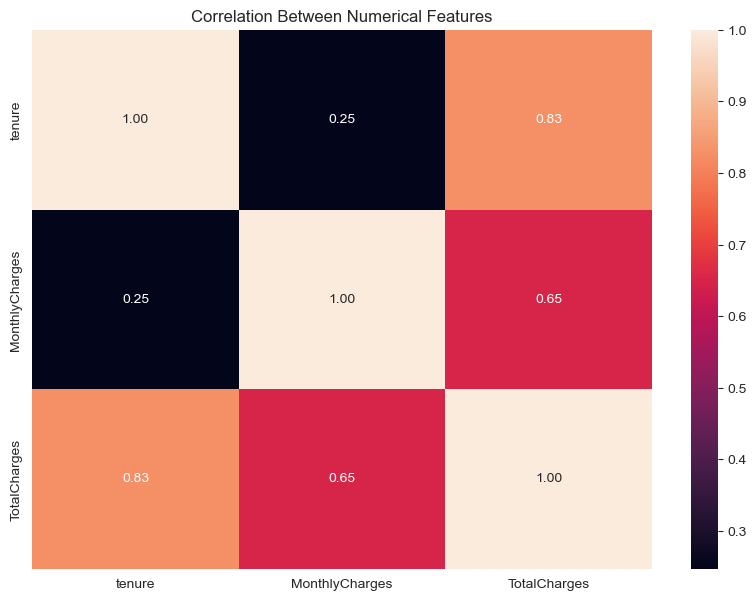

In [49]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)
plt.title("Correlation Between Numerical Features")
plt.show()

In [50]:
X_vif = eda[["tenure", "MonthlyCharges", "TotalCharges"]].copy()

X_vif = X_vif.assign(const=1)

vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_results

,Feature,VIF
0,tenure,5.84
1,MonthlyCharges,3.23
2,TotalCharges,9.53
3,const,14.97


In [51]:
X_vif_reduced = eda[["tenure", "MonthlyCharges"]].copy()
X_vif_reduced = X_vif_reduced.assign(const=1)

vif_reduced = pd.DataFrame({
    "Feature": X_vif_reduced.columns,
    "VIF": [
        variance_inflation_factor(X_vif_reduced.values, i)
        for i in range(X_vif_reduced.shape[1])
    ]
})

vif_reduced

,Feature,VIF
0,tenure,1.06
1,MonthlyCharges,1.06
2,const,6.30


#### Finding

`TotalCharges` is strongly correlated with `tenure` (approximately 0.83) and
also shows substantial correlation with `MonthlyCharges`.

The VIF analysis further indicates that `TotalCharges` contributes considerable
multicollinearity among the numerical predictors. After removing
`TotalCharges`, the VIF values for `tenure` and `MonthlyCharges` decrease to
approximately 1, indicating little remaining multicollinearity between them.

Since `TotalCharges` largely reflects accumulated charges over a customer's
tenure, while `tenure` and `MonthlyCharges` provide more directly interpretable
information, `TotalCharges` will be excluded from the modeling feature set.

### 3.5 Feature Selection Summary

The exploratory and relationship analyses were used to identify features that
should be retained, excluded, or evaluated further during modeling.

Feature-selection decisions were based on a combination of statistical
association, practical churn-rate differences, conditional relationships,
feature redundancy, and multicollinearity.

In [53]:
# Final feature set carried forward to model development
selected_features = [
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "MonthlyCharges"
]

target = "Churn"

| Decision | Features | Reason |
|---|---|---|
| **Retain** | `tenure`, `MonthlyCharges`, `Contract`, `InternetService`, `OnlineSecurity`, `TechSupport`, `PaperlessBilling` | Showed clear and persistent relationships with churn |
| **Retain for model validation** | `OnlineBackup`, `Dependents`, `PaymentMethod`, `Partner`, `DeviceProtection`, `StreamingTV`, `StreamingMovies`, `MultipleLines` | Potentially useful, but their contribution may overlap with or depend on other features |
| **Retain as binary feature** | `SeniorCitizen` | Represents customer demographic information and will be evaluated during modeling |
| **Exclude** | `gender` | Very small churn-rate difference and no significant association with churn |
| **Exclude** | `PhoneService` | Structurally redundant with `MultipleLines` |
| **Exclude** | `TotalCharges` | Strong multicollinearity with the other numerical predictors, particularly `tenure` |
| **Exclude** | `customerID` | Unique identifier with no meaningful predictive interpretation |


Features retained for model validation are not assumed to be important simply
because they are included. Instead, they are carried forward so that their
predictive contribution can be evaluated jointly with the other variables
during model development.

The resulting feature set provides the basis for preprocessing and model
training in the next section.

## 4. Data Preprocessing

The selected features are prepared for machine learning by simplifying
structural categories, defining the predictor and target variables, splitting
the data into training, validation, and test sets, and applying the appropriate
encoding and scaling transformations.

### 4.1 Structural Category Simplification

Before model development, the internet add-on variables are simplified by
replacing `"No internet service"` with `"No"`.

The `InternetService` feature already identifies customers without internet
service, so retaining a separate `"No internet service"` category in each
internet add-on variable would repeat information already represented elsewhere.

This transformation is based only on the meaning of the categories and does
not use the target variable or any statistics calculated from the data.

In [56]:
# Start fresh from the original data after completing the exploratory analysis
model_data = churn_data.copy()

# Simplify the structural "No internet service" category.
# InternetService already records whether internet service is present.
model_data[internet_addons] = (
    model_data[internet_addons]
    .replace("No internet service", "No")
)

# Confirm that the internet add-ons now contain only Yes/No
for col in internet_addons:
    print(f"{col}: {model_data[col].unique()}")

OnlineSecurity: ['No' 'Yes']
OnlineBackup: ['Yes' 'No']
DeviceProtection: ['No' 'Yes']
TechSupport: ['No' 'Yes']
StreamingTV: ['No' 'Yes']
StreamingMovies: ['No' 'Yes']


### 4.2 Feature Matrix and Target Variable

The features retained during the feature-selection stage are used to construct
the predictor matrix `X`, while `Churn` is used as the target variable `y`.

For modeling, the target is converted to binary form:

- `1` = customer churned
- `0` = customer remained

The customer identifier and features excluded during the earlier analysis are
not included in the predictor matrix.

In [58]:
# Use the feature set selected during feature analysis
X = model_data[selected_features].copy()

# Encode the target:
# 1 = customer churned
# 0 = customer remained
y = model_data[target].map({
    "Yes": 1,
    "No": 0
})

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Predictor shape: (7032, 16)
Target shape: (7032,)

Target distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64


The predictor matrix `X` contains the 16 features retained during feature
selection. The target variable `Churn` was encoded as `1` for customers who
churned and `0` for customers who remained.

This makes churn (`1`) the positive class during model evaluation.

### 4.3 Training, Validation, and Test Split

The dataset is divided into training, validation, and test sets using a
70%–15%–15% split.

The **training set** is used to fit the models and perform cross-validation,
while the **validation set** is used for model comparison and classification
threshold selection. The **test set** is kept untouched until the final model
and threshold have been selected.

Stratified splitting is used to preserve approximately the same proportion of
churners and non-churners in each subset. A fixed random state is also used to
make the split reproducible.

In [59]:
# First split: 70% training, 30% temporary validation/test set
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Second split: divide the remaining 30% equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (4922, 16)
Validation set: (1055, 16)
Test set: (1055, 16)


### 4.4 Feature Types

The selected predictors are separated according to their data type so that
appropriate preprocessing can be applied to each group.

Continuous numerical features will be scaled for models that are sensitive to
feature magnitude, categorical features will be encoded, and `SeniorCitizen`
will remain as a binary numerical variable.

In [60]:
# Categorical features that require encoding
categorical_features = [
    "Partner",
    "Dependents",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

# Continuous numerical features
continuous_features = [
    "tenure",
    "MonthlyCharges"
]

# Already represented numerically as 0/1
binary_features = [
    "SeniorCitizen"
]

print("Categorical features:", len(categorical_features))
print("Continuous features:", len(continuous_features))
print("Binary features:", len(binary_features))

Categorical features: 13
Continuous features: 2
Binary features: 1


### 4.5 Preprocessing Pipelines

Separate preprocessing pipelines are constructed for linear and tree-based
models. Categorical variables are one-hot encoded for both model types.

For Logistic Regression, continuous numerical features are standardized because
the model is sensitive to differences in feature scale. Tree-based models do
not require feature scaling, so their numerical features are passed through
unchanged.

In [61]:
# Preprocessing for Logistic Regression
# drop="first" removes one reference category from each categorical feature
logistic_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_features
        ),
        (
            "continuous",
            StandardScaler(),
            continuous_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ]
)

In [62]:
# Preprocessing for tree-based models
# All categorical levels are retained because tree models do not require
# a reference category, and numerical features do not require scaling.
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            continuous_features + binary_features
        )
    ]
)

## 5. Model Development and Baseline Evaluation

Multiple classification algorithms are evaluated to determine how effectively
they identify customers at risk of churn.

The initial models are evaluated using their default classification threshold
of 0.50. Because the primary objective is to identify as many actual churners
as possible, recall for the churn class is emphasized. Precision, F1-score,
and the confusion matrix are also examined to understand the trade-off between
detecting churners and incorrectly flagging non-churners.

### 5.1 Logistic Regression

Logistic Regression is used as the first baseline model because it provides a
simple and interpretable approach to binary classification.

The model is trained using the Logistic Regression preprocessing pipeline and
initially evaluated on the validation set using the default classification
threshold of 0.50.

Recall, precision, F1-score, and the confusion matrix are examined, with
particular emphasis on recall for the churn class.

In [63]:
# Combine preprocessing and Logistic Regression into one pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", logistic_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Fit using training data only
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('continuous', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [64]:
# Baseline predictions using the default 0.50 classification threshold
y_val_pred_logistic = logistic_model.predict(X_val)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_logistic))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_logistic))

Confusion Matrix:
[[701  73]
 [112 169]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.91      0.88       774
           1       0.70      0.60      0.65       281

    accuracy                           0.82      1055
   macro avg       0.78      0.75      0.76      1055
weighted avg       0.82      0.82      0.82      1055



In [65]:
# Focus on performance for the churn class (1)
logistic_recall = recall_score(y_val, y_val_pred_logistic)
logistic_precision = precision_score(y_val, y_val_pred_logistic)
logistic_f1 = f1_score(y_val, y_val_pred_logistic)

print(f"Recall:    {logistic_recall:.3f}")
print(f"Precision: {logistic_precision:.3f}")
print(f"F1-score:  {logistic_f1:.3f}")

Recall:    0.601
Precision: 0.698
F1-score:  0.646


#### Baseline Logistic Regression

At the default classification threshold of 0.50, Logistic Regression achieved
approximately 60% recall for the churn class. This means that the model
identified 169 of the 281 customers who actually churned, while 112 churners
were incorrectly classified as non-churners.

Although precision was approximately 70%, the relatively large number of
false negatives is undesirable for the retention objective of this project.

Therefore, alternative classification thresholds will be evaluated to
determine whether recall can be improved while maintaining a reasonable level
of precision.

In [66]:
# Predicted probability of belonging to the churn class
y_val_prob_logistic = logistic_model.predict_proba(X_val)[:, 1]

# Evaluate the recall-precision trade-off at different thresholds
thresholds = [0.50, 0.45, 0.40, 0.35, 0.30, 0.25]

threshold_results = []

for threshold in thresholds:
    y_pred = (y_val_prob_logistic >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Recall": recall_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred)
    })

threshold_results = pd.DataFrame(threshold_results)
threshold_results.round(3)

,Threshold,Recall,Precision,F1-score
0,0.50,0.60,0.70,0.65
1,0.45,0.66,0.66,0.66
2,0.40,0.70,0.63,0.66
3,0.35,0.74,0.58,0.65
4,0.30,0.78,0.54,0.64
5,0.25,0.83,0.51,0.63


### 5.2 Logistic Regression Threshold Analysis

Lowering the classification threshold increased the proportion of actual
churners identified by the model, but this improvement in recall was accompanied
by a reduction in precision.

A threshold of 0.40 produced a useful initial balance, increasing recall from
approximately 60% to 71% while maintaining precision of approximately 63%.
It also produced the highest F1-score among the thresholds evaluated.

However, the threshold is not finalized at this stage. Additional models and
class-imbalance strategies will be evaluated before selecting the final model
and decision threshold.

### 5.3 Random Forest

Random Forest is evaluated as a tree-based alternative to Logistic Regression.
It can capture nonlinear relationships and interactions between customer
characteristics without requiring the numerical features to be standardized.

The model is first evaluated at the default classification threshold of 0.50.
Additional thresholds are then examined to determine whether improved churn
recall can be achieved while maintaining a reasonable level of precision.

In [67]:
# Random Forest uses the tree-based preprocessing pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42
        ))
    ]
)

# Train using training data only
random_forest_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [68]:
# Baseline predictions at the default 0.50 threshold
y_val_pred_rf = random_forest_model.predict(X_val)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))

print("Recall:   ", round(recall_score(y_val, y_val_pred_rf), 3))
print("Precision:", round(precision_score(y_val, y_val_pred_rf), 3))
print("F1-score: ", round(f1_score(y_val, y_val_pred_rf), 3))

Confusion Matrix:
[[669 105]
 [135 146]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.85       774
           1       0.58      0.52      0.55       281

    accuracy                           0.77      1055
   macro avg       0.71      0.69      0.70      1055
weighted avg       0.77      0.77      0.77      1055

Recall:    0.52
Precision: 0.582
F1-score:  0.549


#### Random Forest Threshold Analysis

In [69]:
# Predicted probability of belonging to the churn class
y_val_prob_rf = random_forest_model.predict_proba(X_val)[:, 1]

# Evaluate different classification thresholds
rf_threshold_results = []

for threshold in thresholds:
    y_pred = (y_val_prob_rf >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Recall": recall_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred)
    })

rf_threshold_results = pd.DataFrame(rf_threshold_results)
rf_threshold_results.round(3)

,Threshold,Recall,Precision,F1-score
0,0.50,0.52,0.58,0.55
1,0.45,0.57,0.58,0.57
2,0.40,0.63,0.57,0.59
3,0.35,0.68,0.54,0.60
4,0.30,0.74,0.52,0.61
5,0.25,0.80,0.49,0.61


#### Random Forest Evaluation

Random Forest was also evaluated across multiple classification thresholds.
As with Logistic Regression, lowering the threshold increased recall while
reducing precision.

The results allow the Random Forest recall–precision trade-off to be compared
with Logistic Regression under the same validation data. Model selection will
not be based on the default 0.50 threshold alone, since the project's primary
objective places greater importance on identifying actual churners.

### 5.4 Gradient Boosting

Gradient Boosting is evaluated as an additional nonlinear model. Unlike Random
Forest, which combines independently constructed trees, Gradient Boosting
builds trees sequentially so that later trees focus on improving the errors of
the existing model.

The model is initially evaluated using its default parameters and a
classification threshold of 0.50.

In [70]:
# Gradient Boosting uses the tree-based preprocessing pipeline
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        ("classifier", GradientBoostingClassifier(
            random_state=42
        ))
    ]
)

# Train using training data only
gradient_boosting_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [71]:
# Baseline predictions at the default 0.50 threshold
y_val_pred_gb = gradient_boosting_model.predict(X_val)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_gb))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_gb))

print("Recall:   ", round(recall_score(y_val, y_val_pred_gb), 3))
print("Precision:", round(precision_score(y_val, y_val_pred_gb), 3))
print("F1-score: ", round(f1_score(y_val, y_val_pred_gb), 3))

Confusion Matrix:
[[707  67]
 [133 148]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.88       774
           1       0.69      0.53      0.60       281

    accuracy                           0.81      1055
   macro avg       0.77      0.72      0.74      1055
weighted avg       0.80      0.81      0.80      1055

Recall:    0.527
Precision: 0.688
F1-score:  0.597


In [72]:
# Predicted churn probabilities
y_val_prob_gb = gradient_boosting_model.predict_proba(X_val)[:, 1]

gb_threshold_results = []

for threshold in thresholds:
    y_pred = (y_val_prob_gb >= threshold).astype(int)

    gb_threshold_results.append({
        "Threshold": threshold,
        "Recall": recall_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred)
    })

gb_threshold_results = pd.DataFrame(gb_threshold_results)
gb_threshold_results.round(3)

,Threshold,Recall,Precision,F1-score
0,0.50,0.53,0.69,0.60
1,0.45,0.62,0.67,0.65
2,0.40,0.67,0.64,0.66
3,0.35,0.73,0.58,0.65
4,0.30,0.77,0.54,0.64
5,0.25,0.82,0.51,0.63


#### Gradient Boosting Evaluation

Gradient Boosting showed the same general threshold trade-off observed with
the previous models. Lowering the classification threshold increased recall
but reduced precision.

At the default threshold of 0.50, the model identified approximately 53% of
actual churners. Reducing the threshold to 0.40 increased recall to
approximately 67% while maintaining precision of approximately 64%, producing
the highest F1-score among the evaluated thresholds.

Further reductions in the threshold increased recall but resulted in larger
declines in precision. The final threshold will therefore be selected only
after comparing all candidate modeling strategies.

### 5.5 Balanced Logistic Regression

Because the churn class represents only about 27% of the dataset, standard
Logistic Regression may place greater emphasis on correctly classifying the
majority non-churn class.

To address this imbalance, a second Logistic Regression model is trained using
balanced class weights. This assigns greater importance to errors involving
the minority churn class during model training.

In [73]:
# Logistic Regression with balanced class weights
balanced_logistic_model = Pipeline(
    steps=[
        ("preprocessor", logistic_preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train using training data only
balanced_logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('continuous', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [74]:
# Baseline validation predictions
y_val_pred_balanced = balanced_logistic_model.predict(X_val)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_balanced))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_balanced))

print("Recall:   ", round(recall_score(y_val, y_val_pred_balanced), 3))
print("Precision:", round(precision_score(y_val, y_val_pred_balanced), 3))
print("F1-score: ", round(f1_score(y_val, y_val_pred_balanced), 3))

Confusion Matrix:
[[570 204]
 [ 51 230]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.74      0.82       774
           1       0.53      0.82      0.64       281

    accuracy                           0.76      1055
   macro avg       0.72      0.78      0.73      1055
weighted avg       0.81      0.76      0.77      1055

Recall:    0.819
Precision: 0.53
F1-score:  0.643


In [75]:
# Predicted churn probabilities from the balanced model
y_val_prob_balanced = balanced_logistic_model.predict_proba(X_val)[:, 1]

# Evaluate different classification thresholds
balanced_thresholds = [0.60, 0.55, 0.50, 0.45, 0.40]

balanced_threshold_results = []

for threshold in balanced_thresholds:
    y_pred = (y_val_prob_balanced >= threshold).astype(int)

    balanced_threshold_results.append({
        "Threshold": threshold,
        "Recall": recall_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred)
    })

balanced_threshold_results = pd.DataFrame(balanced_threshold_results)
balanced_threshold_results.round(3)

,Threshold,Recall,Precision,F1-score
0,0.60,0.74,0.58,0.65
1,0.55,0.77,0.55,0.64
2,0.50,0.82,0.53,0.64
3,0.45,0.84,0.50,0.62
4,0.40,0.87,0.46,0.60


#### Balanced Logistic Regression Evaluation

Applying balanced class weights substantially improved the model's ability to
identify churners. At the default threshold of 0.50, recall increased to
approximately 82%, although precision decreased to approximately 53%.

Further reductions in the classification threshold increased recall, but the
additional improvement came with increasingly large reductions in precision.
For example, a threshold of 0.40 achieved approximately 87% recall but only
46% precision.

A threshold of 0.50 therefore provides a strong candidate for the project
objective, offering high churn detection while avoiding the larger precision
loss associated with lower thresholds. Final model selection will be made
after comparing the candidate models.

### 5.6 Model Comparison

The candidate models are compared using validation-set performance at selected
classification thresholds.

Because the project prioritizes identifying customers who are likely to churn,
recall is given particular importance. Precision and F1-score are also
considered to ensure that improvements in recall do not result in an excessive
number of false-positive predictions.

In [76]:
# Selected operating thresholds based on validation performance
model_candidates = {
    "Logistic Regression": (y_val_prob_logistic, 0.40),
    "Random Forest": (y_val_prob_rf, 0.35),
    "Gradient Boosting": (y_val_prob_gb, 0.35),
    "Balanced Logistic Regression": (y_val_prob_balanced, 0.50)
}

comparison_results = []

for model_name, (probabilities, threshold) in model_candidates.items():
    y_pred = (probabilities >= threshold).astype(int)

    comparison_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Recall": recall_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred)
    })

model_comparison = (
    pd.DataFrame(comparison_results)
    .sort_values("Recall", ascending=False)
    .reset_index(drop=True)
)

model_comparison.round(3)

,Model,Threshold,Recall,Precision,F1-score
0,Balanced Logistic Regression,0.50,0.82,0.53,0.64
1,Gradient Boosting,0.35,0.73,0.58,0.65
2,Logistic Regression,0.40,0.70,0.63,0.66
3,Random Forest,0.35,0.68,0.54,0.60


### 5.7 Hyperparameter Tuning

Balanced Logistic Regression is selected for further optimization because it
provides the strongest recall among the candidate models while maintaining a
reasonable precision-recall trade-off.

Hyperparameter tuning is performed using stratified cross-validation on the
training data only. Recall is used as the optimization metric because
identifying actual churners is the primary modeling objective.

In [77]:
# Define stratified cross-validation to preserve the churn proportion
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Values of C to evaluate
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

# Tune the balanced Logistic Regression using recall
grid_search = GridSearchCV(
    estimator=balanced_logistic_model,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best C:", grid_search.best_params_["classifier__C"])
print("Best Cross-Validation Recall:", round(grid_search.best_score_, 3))

Best C: 1
Best Cross-Validation Recall: 0.8


In [78]:
# Retain the best model identified during cross-validation
tuned_balanced_logistic = grid_search.best_estimator_

In [79]:
# Generate churn probabilities using the tuned model
y_val_prob_tuned = tuned_balanced_logistic.predict_proba(X_val)[:, 1]

In [80]:
# Evaluate the tuned model at the candidate threshold of 0.50
final_threshold = 0.50

y_val_pred_tuned = (
    y_val_prob_tuned >= final_threshold
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_tuned))

print("Recall:   ", round(recall_score(y_val, y_val_pred_tuned), 3))
print("Precision:", round(precision_score(y_val, y_val_pred_tuned), 3))
print("F1-score: ", round(f1_score(y_val, y_val_pred_tuned), 3))

Confusion Matrix:
[[570 204]
 [ 51 230]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.74      0.82       774
           1       0.53      0.82      0.64       281

    accuracy                           0.76      1055
   macro avg       0.72      0.78      0.73      1055
weighted avg       0.81      0.76      0.77      1055

Recall:    0.819
Precision: 0.53
F1-score:  0.643


#### Tuned Model Validation

Cross-validation was used to tune the regularization strength of the balanced
Logistic Regression model using recall as the optimization metric.

The tuned model was subsequently evaluated on the validation set using the
selected classification threshold of 0.50. Its performance was compared with
the earlier balanced model to confirm that the final configuration maintained
the desired high recall without an excessive loss of precision.

Following this validation step, the model configuration and classification
threshold are fixed before evaluation on the previously untouched test set.

## 6. Final Model Evaluation

After model selection, hyperparameter tuning, and threshold selection were
completed using the training and validation data, the final model is evaluated
on the previously untouched test set.

No further model or threshold adjustments are made based on test-set
performance. This provides a more realistic estimate of how the selected model
may perform on unseen customers.

In [81]:
# Generate churn probabilities for the untouched test set
y_test_prob = tuned_balanced_logistic.predict_proba(X_test)[:, 1]

# Apply the classification threshold selected using validation data
y_test_pred = (y_test_prob >= final_threshold).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("Recall:   ", round(recall_score(y_test, y_test_pred), 3))
print("Precision:", round(precision_score(y_test, y_test_pred), 3))
print("F1-score: ", round(f1_score(y_test, y_test_pred), 3))

Confusion Matrix:
[[554 221]
 [ 69 211]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.71      0.79       775
           1       0.49      0.75      0.59       280

    accuracy                           0.73      1055
   macro avg       0.69      0.73      0.69      1055
weighted avg       0.78      0.73      0.74      1055

Recall:    0.754
Precision: 0.488
F1-score:  0.593


### Final Test-Set Performance

The final Balanced Logistic Regression model achieved a **recall of 75.4%**,
meaning that it correctly identified approximately three out of every four
customers who actually churned.

The model achieved a **precision of 48.8%**, indicating that approximately
half of the customers predicted as churners actually churned. This lower
precision reflects the trade-off made by prioritizing recall, where the model
is intentionally more sensitive to customers who may be at risk of leaving.

The confusion matrix shows that the model correctly identified **211 of the
280 actual churners**, while **69 churners were missed**. It also incorrectly
classified 221 non-churning customers as potential churners.

Overall, the model achieved an **F1-score of 59.3%** for the churn class.
Given the project objective of reducing missed churners, the final model
provides a reasonable balance between identifying high-risk customers and
limiting unnecessary retention interventions.

## 7. Model Interpretation and Business Insights

After evaluating the predictive performance of the final model, the model
coefficients are examined to understand which customer characteristics are
most strongly associated with higher or lower predicted churn risk.

Because Logistic Regression was used, the direction and magnitude of the
model coefficients can provide insight into how individual features contribute
to churn predictions, while holding the other model features constant.

In [82]:
# Extract the fitted preprocessing and Logistic Regression steps
final_preprocessor = tuned_balanced_logistic.named_steps["preprocessor"]
final_classifier = tuned_balanced_logistic.named_steps["classifier"]

# Get the feature names created after preprocessing
feature_names = final_preprocessor.get_feature_names_out()

# Extract the Logistic Regression coefficients
coefficients = final_classifier.coef_[0]

# Combine feature names and coefficients into a table
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Rank features by the absolute size of their coefficients
coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = (
    coefficient_table
    .sort_values("Absolute_Coefficient", ascending=False)
    .reset_index(drop=True)
)

coefficient_table.head(15)

,Feature,Coefficient,Absolute_Coefficient
0,categorical__Contract_Two year,-1.34,1.34
1,categorical__InternetService_No,-0.98,0.98
2,categorical__InternetService_Fiber optic,0.98,0.98
3,continuous__tenure,-0.77,0.77
4,categorical__Contract_One year,-0.72,0.72
5,categorical__PaymentMethod_Electronic check,0.40,0.40
6,categorical__MultipleLines_No phone service,0.38,0.38
7,categorical__OnlineSecurity_Yes,-0.38,0.38
8,categorical__TechSupport_Yes,-0.37,0.37
9,categorical__MultipleLines_Yes,0.35,0.35


### 7.1 Logistic Regression Coefficient Analysis

Because the final selected model is Logistic Regression, its coefficients can
be examined to better understand how the retained features contribute to churn
predictions.

The coefficients are extracted from the fitted model and ranked by their
absolute magnitude. A positive coefficient is associated with higher predicted
churn, while a negative coefficient is associated with lower predicted churn.

For categorical variables, the coefficients are interpreted relative to the
reference category created during one-hot encoding. The results represent
associations within the fitted model and should not be interpreted as direct
causal effects.

### 7.2 Interpretation of Key Model Features

The final model indicates that contract type, internet service, tenure, support
services, and billing characteristics are among the strongest contributors to
predicted churn.

Customers with **one-year and two-year contracts** are associated with lower
predicted churn compared with customers on the reference contract category
(month-to-month). The two-year contract has the largest negative coefficient,
suggesting a particularly strong association with customer retention.

**Longer tenure** is also associated with lower predicted churn, supporting
the earlier exploratory finding that customers who have remained with the
company for longer periods are generally less likely to churn.

For internet service, **fiber-optic service** is associated with higher
predicted churn relative to the reference internet category, while customers
with no internet service show a lower predicted churn tendency.

Customers with **online security** and **technical support** are associated
with lower predicted churn, whereas electronic-check payment and paperless
billing are associated with higher predicted churn.

These coefficients represent associations within the fitted model while
holding the other included features constant. They should therefore not be
interpreted as evidence that any individual feature directly causes churn.

### 7.3 Visualization of Key Model Coefficients

The strongest model coefficients are visualized to compare the direction and
relative magnitude of their associations with predicted churn.

Positive coefficients are associated with higher predicted churn, while
negative coefficients are associated with lower predicted churn.

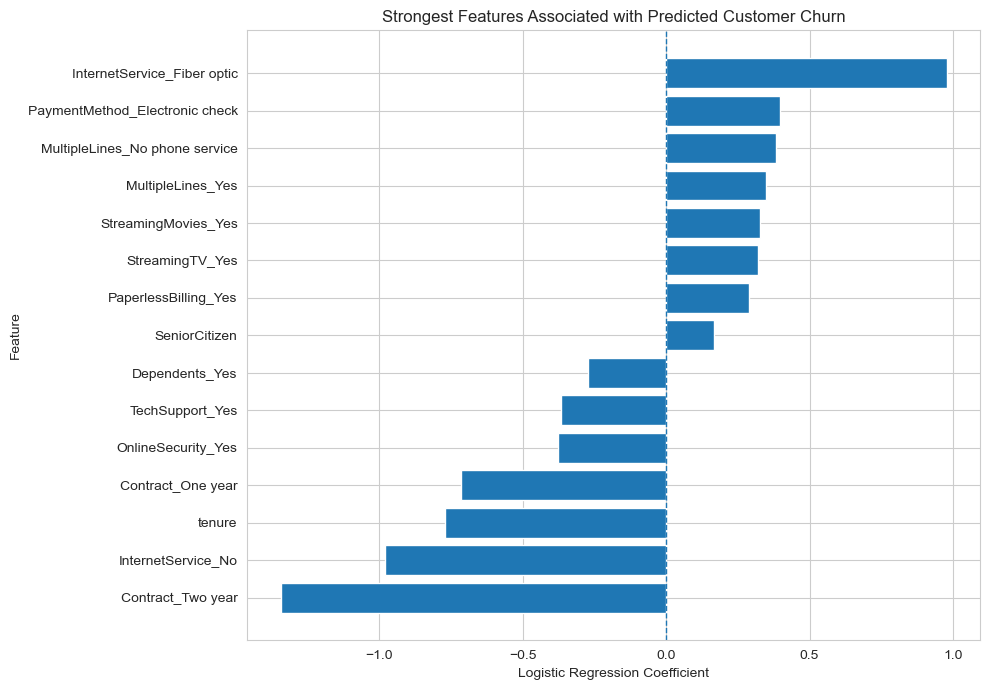

In [83]:
# Select the 15 strongest coefficients identified by absolute magnitude
top_coefficients = coefficient_table.head(15).copy()

# Remove the preprocessing prefixes to make the labels easier to read
top_coefficients["Feature"] = (
    top_coefficients["Feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("continuous__", "", regex=False)
    .str.replace("binary__", "", regex=False)
)

# Sort for a clearer horizontal plot
top_coefficients = top_coefficients.sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"]
)

# Add a reference line at zero
plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Strongest Features Associated with Predicted Customer Churn")

plt.tight_layout()
plt.show()

### 8.1 Business Recommendations

Based on the exploratory analysis and the final predictive model, the following
areas may be useful for customer-retention strategies:

- **Prioritize customers on month-to-month contracts.** Longer-term contracts,
  particularly two-year contracts, were associated with substantially lower
  predicted churn. Customers remaining on month-to-month arrangements may
  therefore represent an important group for targeted retention efforts.

- **Focus on customers in the early stages of their relationship.** Longer
  tenure was associated with lower predicted churn, suggesting that newer
  customers may benefit from additional engagement and retention support.

- **Investigate the experience of fiber-optic customers.** Fiber-optic internet
  was associated with higher predicted churn even after other model features
  were considered. Further investigation into pricing, service quality, or
  customer satisfaction within this group may help identify the underlying
  reasons.

- **Consider support-related services in retention strategies.** Online
  security and technical support were associated with lower predicted churn.
  Their relationship with customer retention may therefore be worth further
  investigation.

- **Use billing and payment characteristics as risk indicators.** Electronic
  check payment and paperless billing were associated with higher predicted
  churn and may help identify customers who require additional attention.

These findings identify useful customer segments and risk indicators, but they
do not establish that changing any individual feature will directly prevent
churn. Further business investigation or controlled experiments would be
required before drawing causal conclusions.